# SHAPによる回帰予測値の要因分解(California Housing × LightGBM)

このノートブックは、アプリケーション側(`src/app_california`)のパイプラインを1ステップずつ呼び出して、結果を表示します。結論と解釈は `outputs/report.md` にまとめています。

| 層 | 場所 | 役割 |
|---|---|---|
| アプリケーション | `src/app_california/` | このデータ固有の部分: 設定(`config.py`)、データ読込、モデル定義、分析の流れ(`pipeline.py`) |
| プラットフォーム | `src/xai_platform/` | 汎用のI/F: SHAP計算・加法性チェック・What-if・作図・保存 |

- **ミクロ**: 1サンプルの予測値を「ベースライン + 各特徴量の寄与」に分解します。
- **What-if**: 特徴量を動かしてモデルに再予測させ、Δ予測値を求めます。さらに、そのΔ予測値をΔSHAPで分解します。
- **マクロ**: 寄与の分布、非線形な効果、相互作用、特徴量グループ別の構成を見ます。

> 数値の単位は目的変数(MedHouseVal)の単位で、**1.0 = 10万ドル**です。SHAPが説明するのは「モデルの予測」であり、現実の因果関係ではありません。

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import shap
from src.app_california import config
from src.app_california.pipeline import CaliforniaAnalysis

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 200)
print("shap", shap.__version__)
A = CaliforniaAnalysis()

shap 0.49.1


## 1. データ

訓練データとテストデータを80/20で分割します(`random_state=42`)。特徴量の意味は下表のとおりです。

In [2]:
A.step_data().show()

train (16512, 8) test (4128, 8)
目的変数が上限5.0で打ち切られている割合(train): 0.0489
■ 特徴量の説明  [生成I/F: xai_platform.data.description_table]


,特徴量,説明
0,MedInc,地区の世帯収入中央値(単位: 1万ドル)
1,HouseAge,地区の住宅築年数の中央値(年)
2,AveRooms,1世帯あたり平均部屋数
3,AveBedrms,1世帯あたり平均寝室数
4,Population,地区の人口
5,AveOccup,1世帯あたり平均居住人数
6,Latitude,緯度(大きいほど北)
7,Longitude,経度(大きいほど東=内陸)


## 2. モデルの学習と評価(テストデータ)

性能が低いモデルを説明しても意味が薄いので、先に性能を確認します。Ridgeは、SHAPの実装が正しいかを検証するためだけに使います。

In [3]:
A.step_models().show()

■ テストデータでの性能  [生成I/F: xai_platform.model.evaluation_table]


,R2,RMSE,MAE
モデル,,,
LightGBM,0.8587,0.4302,0.2805
Ridge,0.5759,0.7455,0.5332


## 3. SHAP値の計算と検証

- `TreeExplainer` の `expected_value` がベースラインです。これは訓練データの平均予測で、「0」や「標準的な家」ではありません。
- **加法性チェック**: すべてのテストサンプルで `|ベースライン + ΣSHAP − predict| < 1e-6` を確認します。
- **Ridgeでの検証**: 線形モデルではSHAP値が `係数 × (x − 訓練平均)` に一致するはずなので、それを確認します。

In [4]:
A.step_shap_validation().show()

ベースライン expected_value = 2.071947 / 訓練データの平均予測 = 2.071947 / 差 = 0.00e+00
加法性チェック: {'サンプル数': 4128, '許容誤差': 1e-06, '最大絶対誤差': 3.697042672001771e-14, '合格数': 4128, '全件合格': True}
Ridge: ベースライン誤差 1.33e-15
■ Ridge: SHAP値 vs 係数×(x−平均)  [生成I/F: xai_platform.explain.linear_shap_check]


,係数,最大絶対差(SHAP vs 係数×(x−平均))
MedInc,0.4485,0.0000
HouseAge,0.0097,0.0000
AveRooms,-0.1230,0.0000
AveBedrms,0.7814,0.0000
Population,-0.0000,0.0000
AveOccup,-0.0035,0.0000
Latitude,-0.4198,0.0000
Longitude,-0.4337,0.0000


## 4. 予測値の分解(ミクロ)

代表サンプルは、テストデータの予測値の **95%点・50%点・5%点に最も近いサンプル** とします(`config.REPRESENTATIVES`)。最大値・最小値を選ばないのは、目的変数が上限5.0で打ち切られている影響や、極端な外れ値の影響を避けるためです。

■ 予測が高い(95%点): ベースライン2.072(約20.7万ドル)に対し、AveOccup(=1.89)が+0.837(約+8.4万ドル)、Latitude(=34.1)が+0.683(約+6.8万ドル)、Longitude(=-118)が+0.345(約+3.5万ドル)、その他5特徴量の合計が+0.293(約+2.9万ドル)で、予測は4.231(約42.3万ドル)。
■ 中央値付近(50%点): ベースライン2.072(約20.7万ドル)に対し、Longitude(=-118)が−0.500(約−5.0万ドル)、MedInc(=5.25)が+0.207(約+2.1万ドル)、Latitude(=33.8)が+0.097(約+1.0万ドル)、その他5特徴量の合計が−0.048(約−0.5万ドル)で、予測は1.828(約18.3万ドル)。
■ 予測が低い(5%点): ベースライン2.072(約20.7万ドル)に対し、Latitude(=36.8)が−0.678(約−6.8万ドル)、MedInc(=2.67)が−0.358(約−3.6万ドル)、Longitude(=-120)が−0.192(約−1.9万ドル)、その他5特徴量の合計が−0.110(約−1.1万ドル)で、予測は0.734(約7.3万ドル)。
■ 代表サンプル  [生成I/F: xai_platform.explain.select_representatives]


,区分,分位点,分位点の予測値,サンプルindex,予測値
0,予測が高い(95%点),0.9500,4.2298,4084,4.2305
1,中央値付近(50%点),0.5000,1.8270,10342,1.8279
2,予測が低い(5%点),0.0500,0.7341,2140,0.7341


■ 分解表: 予測が高い(95%点)(index 4084、実測値 3.944)  [生成I/F: xai_platform.explain.decomposition_table]


,特徴量,現在の値,SHAP値,SHAP値(万ドル),累積
0,ベースライン,NaN,NaN,NaN,2.0719
1,AveOccup,1.8879,0.8372,8.3718,2.9091
2,Latitude,34.1500,0.6828,6.8275,3.5919
3,Longitude,-118.3900,0.3453,3.4529,3.9372
4,MedInc,4.2031,0.2049,2.0495,4.1421
5,HouseAge,29.0000,0.1229,1.2295,4.2651
6,AveRooms,4.8442,-0.0290,-0.2897,4.2361
7,AveBedrms,1.0125,-0.0071,-0.0711,4.2290
8,Population,1212.0000,0.0015,0.0154,4.2305
9,予測値 = ベースライン + ΣSHAP,NaN,2.1586,21.5857,4.2305


■ 分解表: 中央値付近(50%点)(index 10342、実測値 2.371)  [生成I/F: xai_platform.explain.decomposition_table]


,特徴量,現在の値,SHAP値,SHAP値(万ドル),累積
0,ベースライン,NaN,NaN,NaN,2.0719
1,Longitude,-117.6900,-0.4998,-4.9980,1.5721
2,MedInc,5.2541,0.2069,2.0688,1.7790
3,Latitude,33.8000,0.0966,0.9657,1.8756
4,HouseAge,5.0000,-0.0882,-0.8816,1.7874
5,AveOccup,2.5250,0.0872,0.8715,1.8746
6,AveRooms,5.4699,-0.0646,-0.6459,1.8100
7,Population,1467.0000,0.0111,0.1112,1.8211
8,AveBedrms,1.0861,0.0068,0.0676,1.8279
9,予測値 = ベースライン + ΣSHAP,NaN,-0.2441,-2.4406,1.8279


■ 分解表: 予測が低い(5%点)(index 2140、実測値 0.704)  [生成I/F: xai_platform.explain.decomposition_table]


,特徴量,現在の値,SHAP値,SHAP値(万ドル),累積
0,ベースライン,NaN,NaN,NaN,2.0719
1,Latitude,36.7700,-0.6778,-6.7784,1.3941
2,MedInc,2.6726,-0.3576,-3.5755,1.0366
3,Longitude,-119.7500,-0.1922,-1.9223,0.8443
4,AveRooms,5.0051,-0.1372,-1.3720,0.7071
5,AveOccup,2.5638,0.0254,0.2538,0.7325
6,Population,1005.0000,-0.0163,-0.1630,0.7162
7,AveBedrms,1.0179,0.0096,0.0956,0.7258
8,HouseAge,32.0000,0.0083,0.0833,0.7341
9,予測値 = ベースライン + ΣSHAP,NaN,-1.3378,-13.3785,0.7341


■ waterfall_high.png  [生成I/F: xai_platform.plots.waterfall]


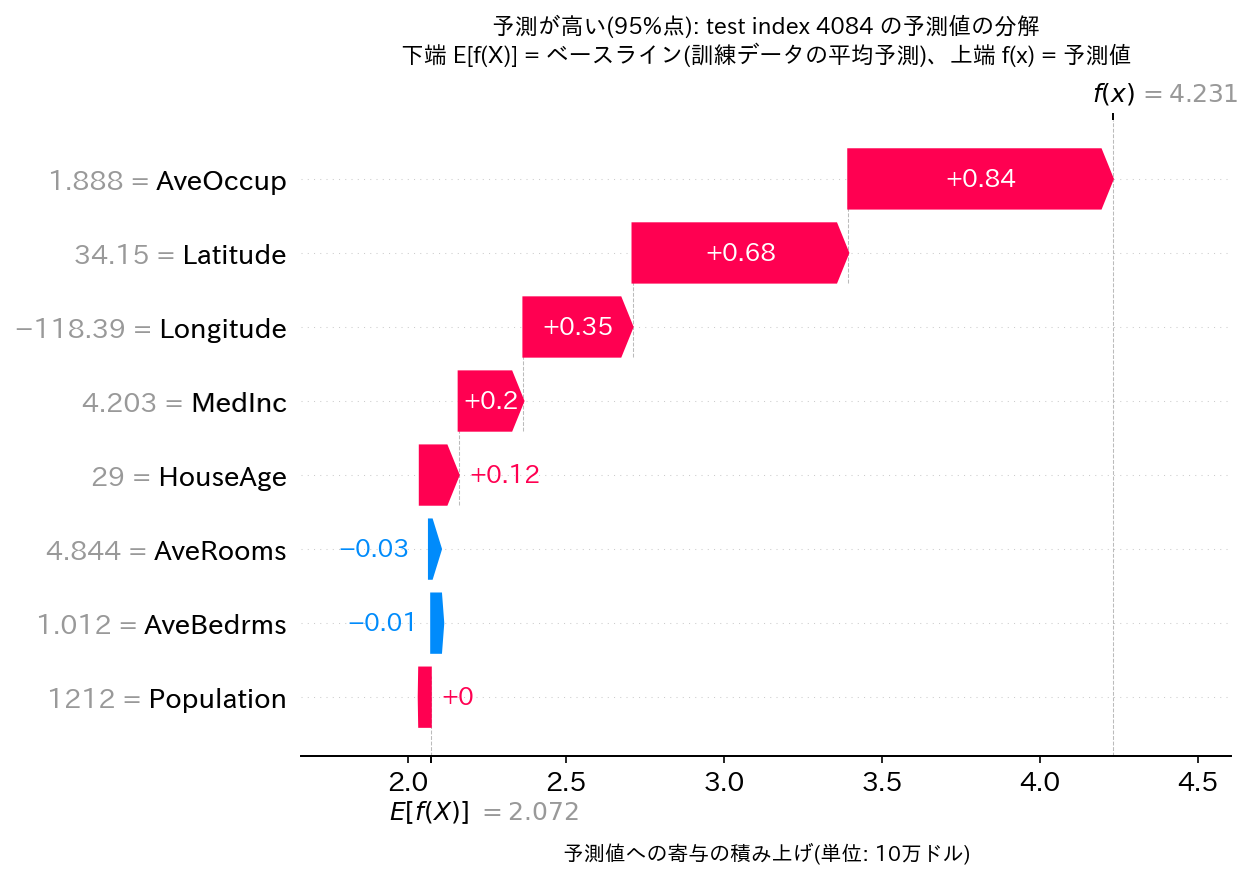

■ waterfall_median.png  [生成I/F: xai_platform.plots.waterfall]


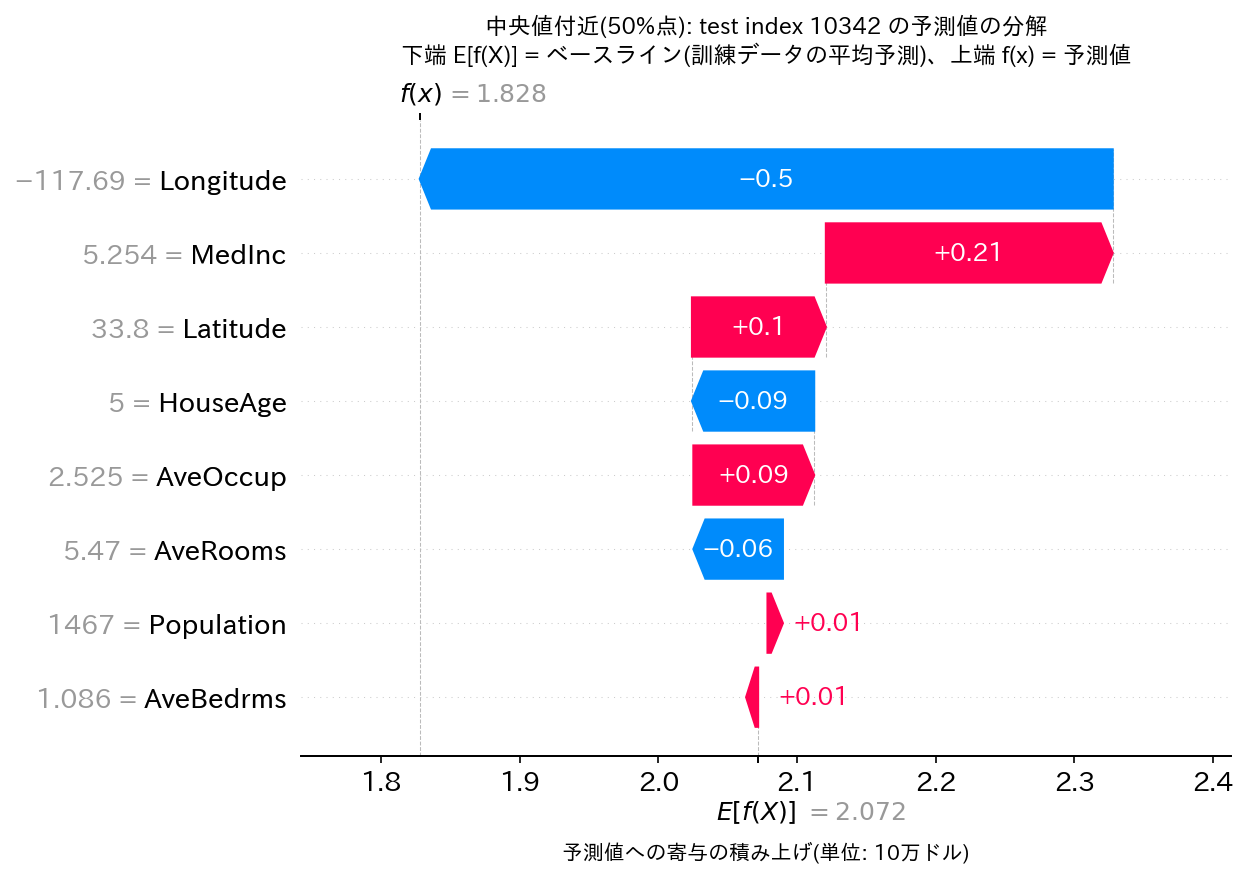

■ waterfall_low.png  [生成I/F: xai_platform.plots.waterfall]


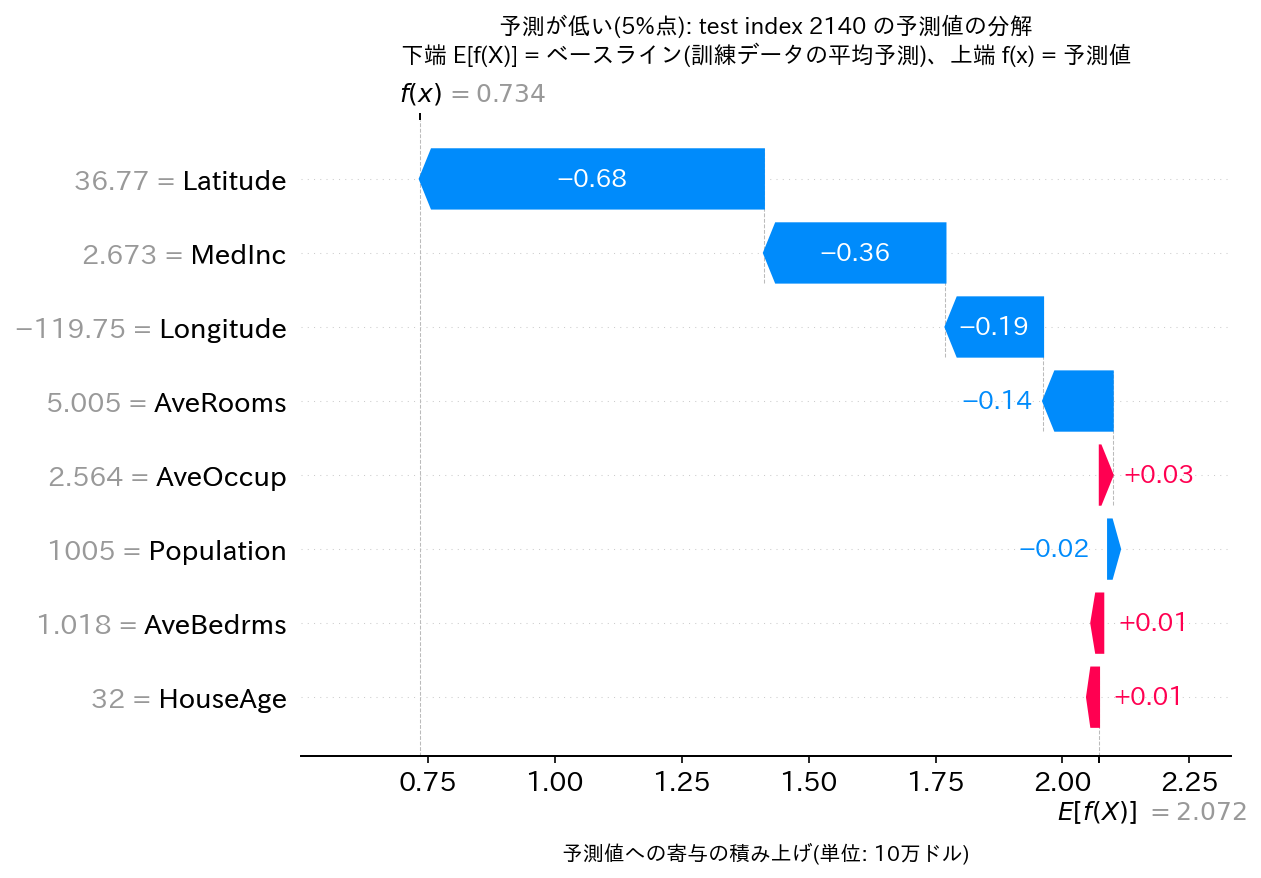

In [5]:
A.step_micro().show()

## 5. What-ifシミュレーション(値を上げるとどうなるか)

SHAP値は「現在の値とデータ平均との差による寄与」であり、**値を動かしたときの変化量そのものではありません**。そこで次のように役割を分けます。

- **(A) 変化量の根拠**: 特徴量を変えて `model.predict` を再実行し、Δ予測値を求めます。
- **(B) 説明**: 変更の前後でSHAP値を再計算し、`Δ予測値 = ΣΔSHAP` の形で分解します。

動かす幅は+1σです。σは、外れ値で膨らまないように訓練データの1〜99パーセンタイルの範囲で計算した頑健な標準偏差です。動かした先は1〜99パーセンタイルの範囲に収め、範囲を超えた場合は「※範囲外→クリップ」と表示します。

■ 頑健σと動かせる範囲  [生成I/F: xai_platform.whatif.ranges_table]


,頑健σ,通常σ,下限(1%),上限(99%)
MedInc,1.6700,1.9043,1.0669,10.5769
HouseAge,12.4729,12.6025,4.0000,52.0000
AveRooms,1.2023,2.3874,2.5782,10.3184
AveBedrms,0.1180,0.4332,0.8712,2.1165
Population,864.7453,1137.0564,88.1100,5798.7200
AveOccup,0.6818,11.5787,1.5388,5.4102
Latitude,2.0646,2.1367,32.6800,40.6489
Longitude,1.9360,2.0057,-123.2389,-116.3100


■ +1σ: 中央値付近(50%点)  [生成I/F: xai_platform.whatif.single_variable_whatif]


,特徴量,元の値,要求値,適用値,外挿警告,変更量,元の予測,変更後の予測,Δ予測値,相関注記
0,MedInc,5.2541,6.9241,6.9241,False,1.6700,1.8279,2.5523,0.7244,
1,Latitude,33.8000,35.8646,35.8646,False,2.0646,1.8279,1.1544,-0.6735,Longitudeと強相関(片方のみ変更)
2,AveRooms,5.4699,6.6722,6.6722,False,1.2023,1.8279,2.3798,0.5519,AveBedrmsと強相関(片方のみ変更)
3,Longitude,-117.6900,-115.7540,-116.3100,True,1.3800,1.8279,1.3607,-0.4671,Latitudeと強相関(片方のみ変更)
4,Population,1467.0000,2331.7453,2331.7453,False,864.7453,1.8279,1.9676,0.1397,
5,HouseAge,5.0000,17.4729,17.4729,False,12.4729,1.8279,1.9402,0.1123,
6,AveBedrms,1.0861,1.2041,1.2041,False,0.1180,1.8279,1.8448,0.0169,AveRoomsと強相関(片方のみ変更)
7,AveOccup,2.5250,3.2068,3.2068,False,0.6818,1.8279,1.8319,0.0040,


■ tornado_sd_high.png  [生成I/F: xai_platform.plots.tornado]


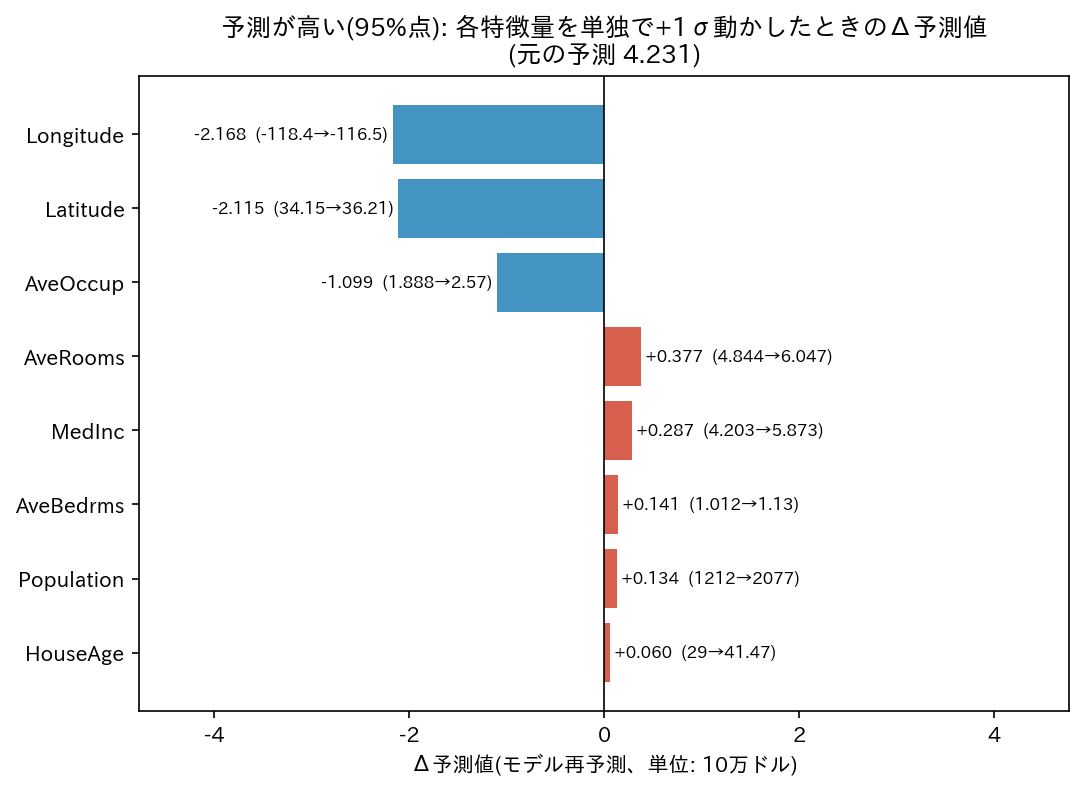

■ tornado_sd_median.png  [生成I/F: xai_platform.plots.tornado]


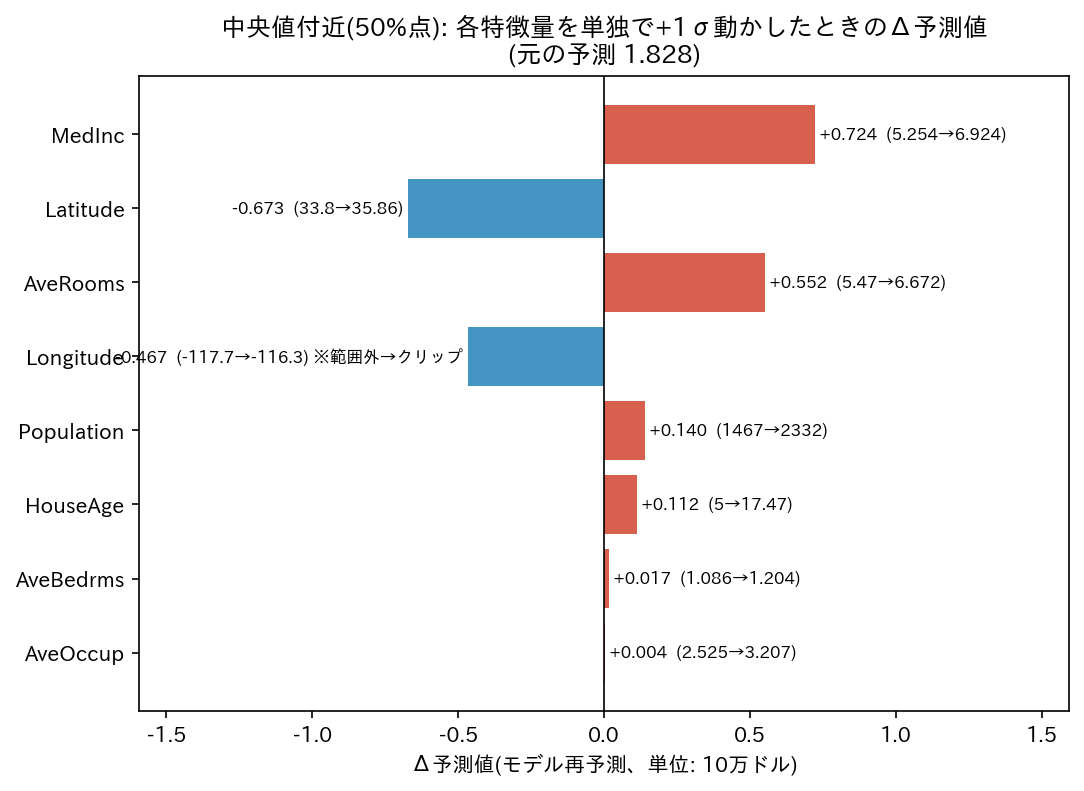

■ tornado_sd_low.png  [生成I/F: xai_platform.plots.tornado]


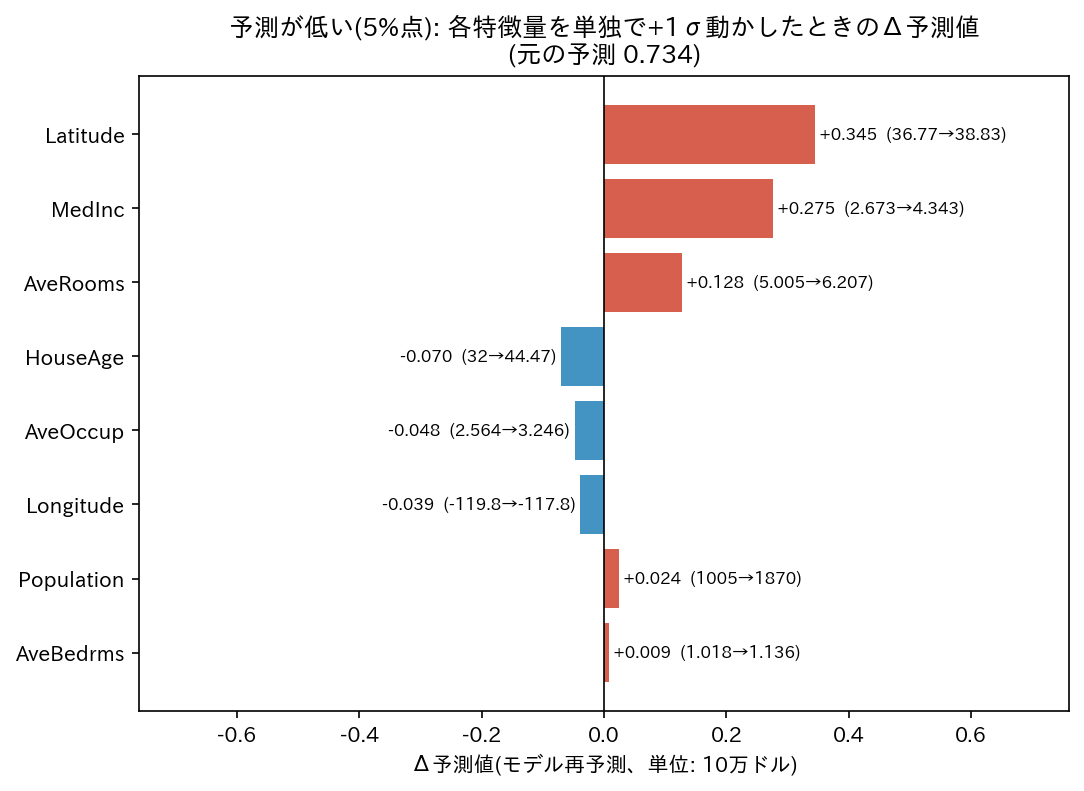

■ tornado_pct10_median.png  [生成I/F: xai_platform.plots.tornado]


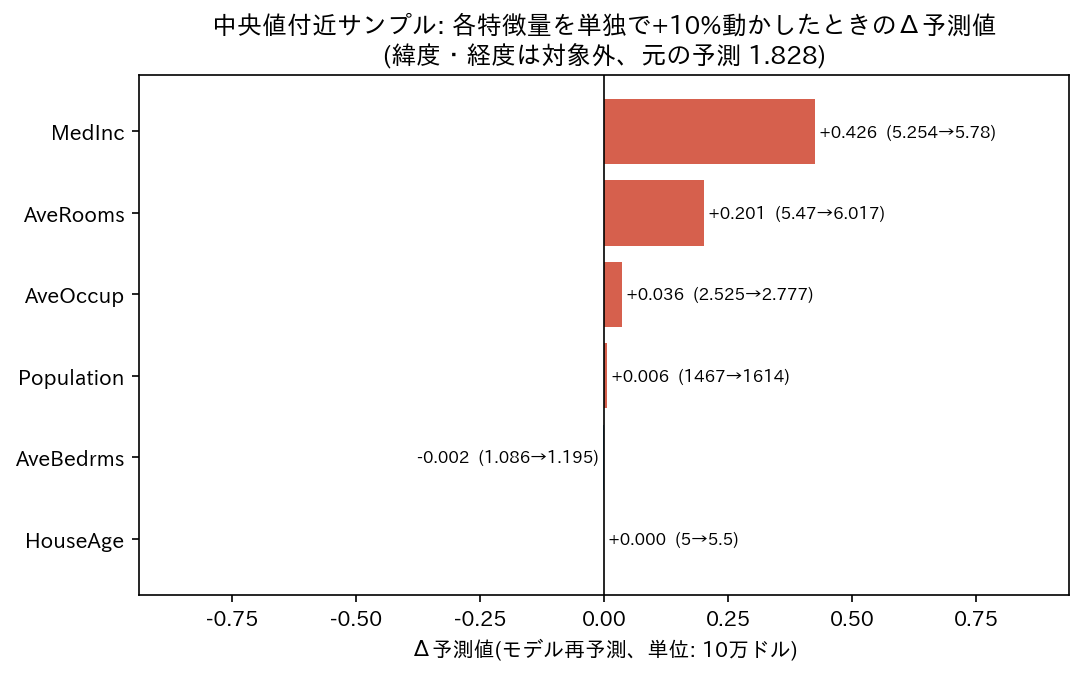

In [6]:
A.step_whatif_single().show()

### 5.2 複数の変数を同時に動かすシナリオと、ΔSHAPによる分解

シナリオは `config.SCENARIOS` で定義しています。

- **相互作用分** = 同時に動かしたときのΔ − 各変数を単独で動かしたときのΔの合計
- ΣΔSHAPはΔ予測値に一致します(ベースラインが共通だからです)。変更していない特徴量のSHAP値が変わることもあり、それは相互作用を通じた効果です。

■ 適用した変更  [生成I/F: xai_platform.whatif.scenario_analysis]


,シナリオ,特徴量,元の値,要求値,適用値,外挿警告
0,S1 所得と広さが上がる,MedInc,5.2541,6.9241,6.9241,False
1,S1 所得と広さが上がる,AveRooms,5.4699,6.6722,6.6722,False
2,S2 築浅・世帯人数が少ない,HouseAge,5.0000,-5.0000,4.0000,True
3,S2 築浅・世帯人数が少ない,AveOccup,2.5250,2.0250,2.0250,False
4,S3 海岸沿いに北西へ移動,Latitude,33.8000,34.8000,34.8000,False
5,S3 海岸沿いに北西へ移動,Longitude,-117.6900,-118.6900,-118.6900,False
6,S4 3変数を同時に変更,MedInc,5.2541,6.9241,6.9241,False
7,S4 3変数を同時に変更,HouseAge,5.0000,-5.0000,4.0000,True
8,S4 3変数を同時に変更,AveOccup,2.5250,2.0250,2.0250,False


■ シナリオ別の結果  [生成I/F: xai_platform.whatif.scenario_analysis]


,シナリオ,元の予測,変更後の予測,Δ予測値(同時),単独Δの合計,相互作用分(同時−単独合計),ΣΔSHAP,単独Δの内訳,外挿警告,相関注記
0,S1 所得と広さが上がる,1.8279,2.9877,1.1599,1.2763,-0.1164,1.1599,"MedInc:+0.724, AveRooms:+0.552",False,片方のみ変更: AveRooms/AveBedrms
1,S2 築浅・世帯人数が少ない,1.8279,2.1442,0.3163,0.3126,0.0037,0.3163,"HouseAge:+0.071, AveOccup:+0.242",True,
2,S3 海岸沿いに北西へ移動,1.8279,1.8219,-0.0060,1.5921,-1.5981,-0.0060,"Latitude:-0.369, Longitude:+1.961",False,
3,S4 3変数を同時に変更,1.8279,2.6396,0.8117,1.0369,-0.2252,0.8117,"MedInc:+0.724, HouseAge:+0.071, AveOccup:+0.242",True,


■ ΔSHAP  [生成I/F: xai_platform.whatif.scenario_analysis]


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
S1 所得と広さが上がる,0.7282,0.0210,0.3049,0.0260,0.0105,0.0029,0.0693,-0.0029
S2 築浅・世帯人数が少ない,0.0738,-0.1714,0.0466,-0.0068,0.0118,0.3502,0.0148,-0.0027
S3 海岸沿いに北西へ移動,0.0436,0.0240,0.0421,-0.0085,0.0190,0.0377,-0.4088,0.2448
S4 3変数を同時に変更,0.6460,-0.1209,0.0188,0.0386,0.0181,0.2398,0.0193,-0.0481


■ scenario_dshap_median.png  [生成I/F: xai_platform.plots.scenario_dshap]


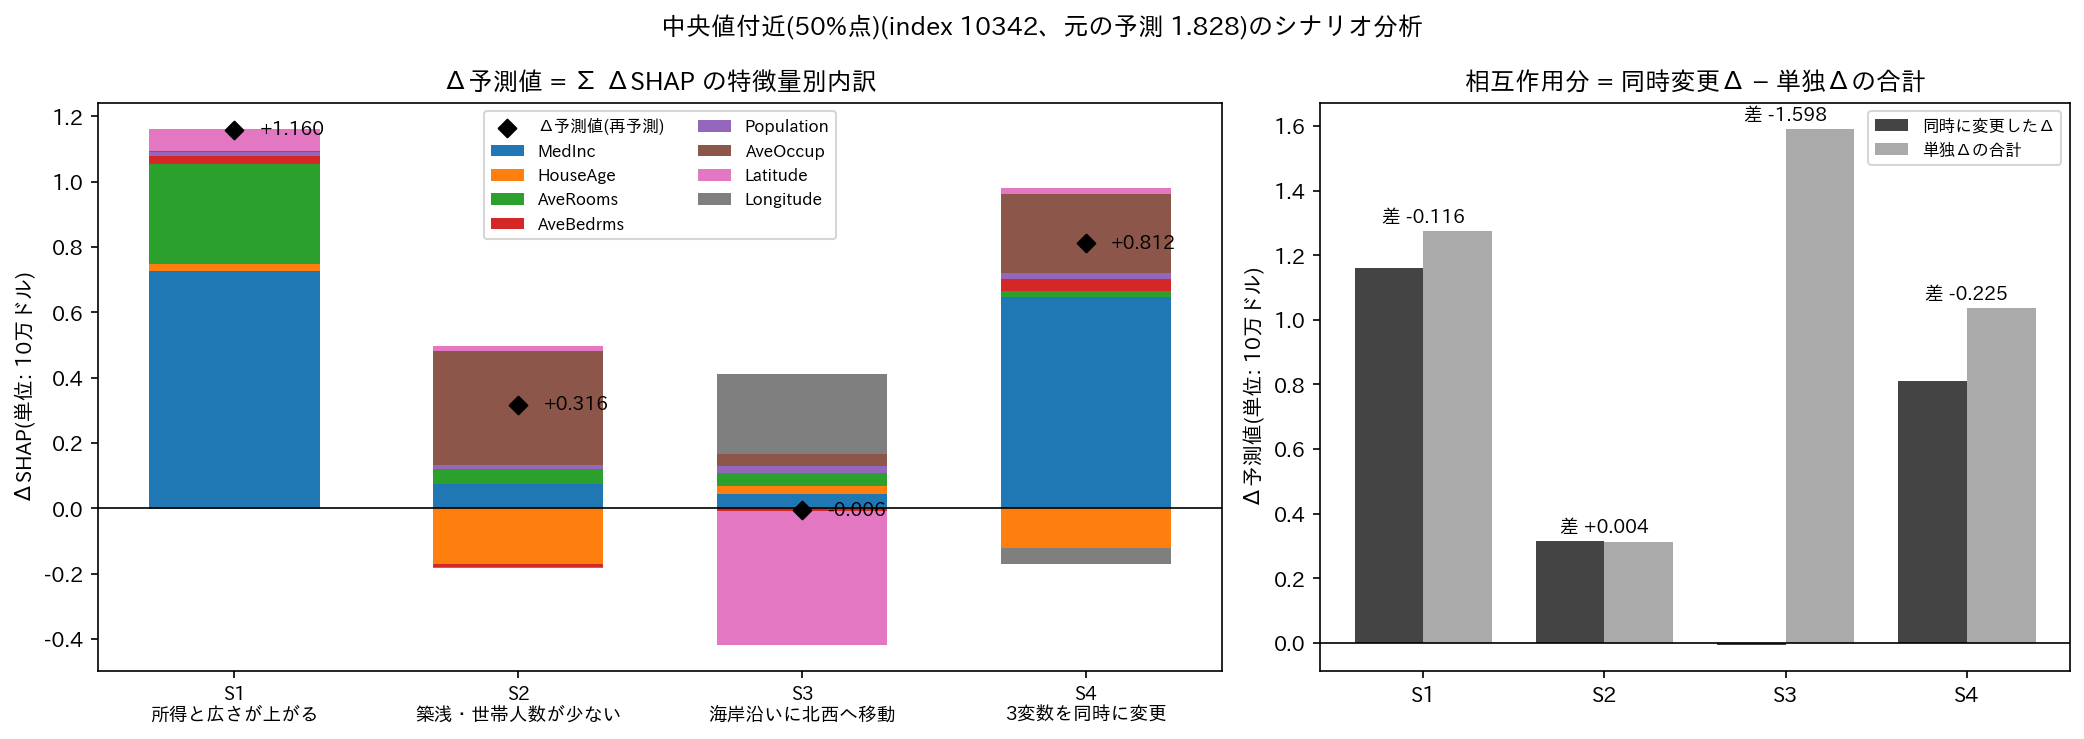

In [7]:
A.step_scenarios().show()

## 6. 全体傾向(マクロ)

### 6.1 beeswarmと平均|SHAP|

平均|SHAP|は「寄与の平均的な大きさ」を表し、寄与の方向は分かりません。方向はbeeswarmで確認します(赤 = 特徴量の値が高い)。

■ beeswarm.png  [生成I/F: xai_platform.plots.beeswarm]


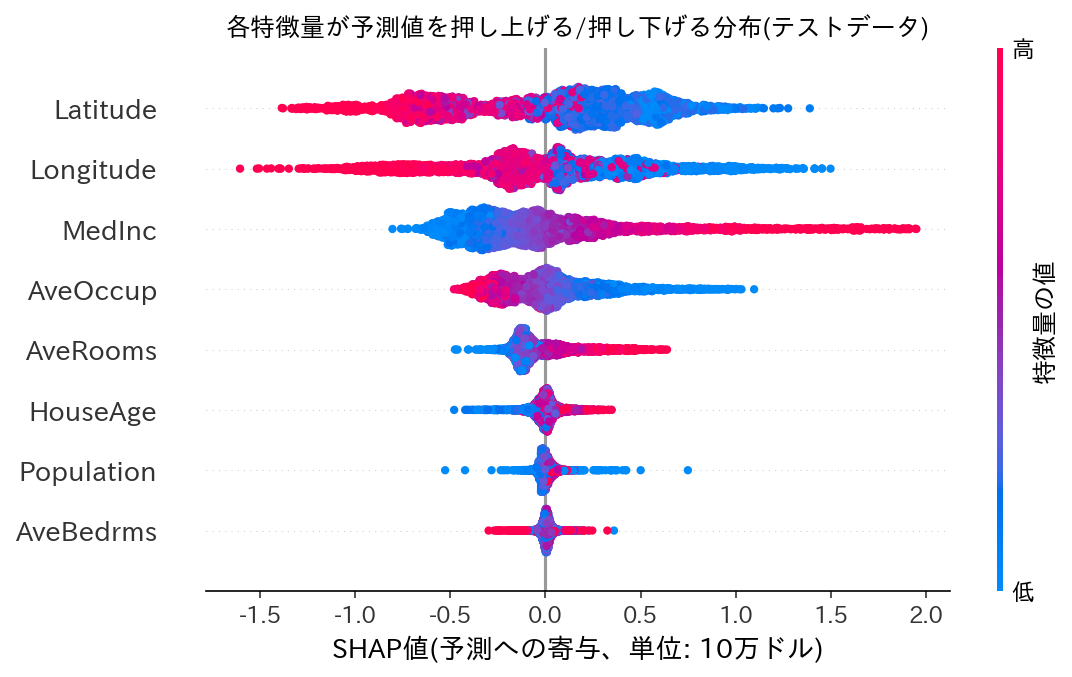

■ mean_abs_shap.png  [生成I/F: xai_platform.plots.mean_abs_bar]


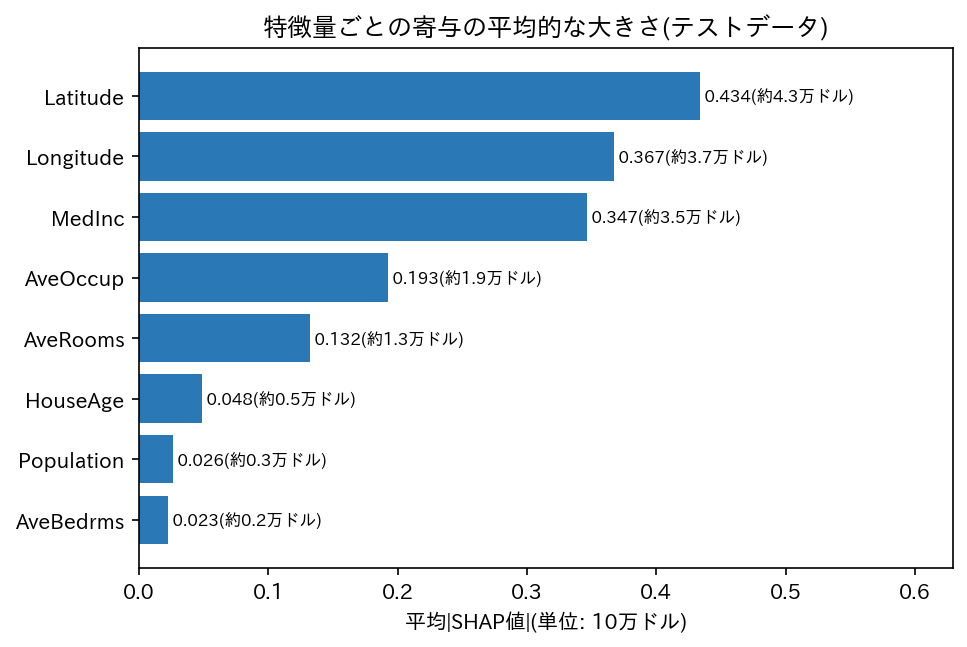

In [8]:
A.step_global().show()

### 6.2 依存プロット(主要な上位6特徴量)

横軸に特徴量の値、縦軸にSHAP値をとります。「この範囲の値だと、予測がいくら上下するか」を読み取るための図です。点の色には、`shap.utils.approximate_interactions` で選んだ、相互作用の最も強い特徴量を使います。表には、値の十分位ごとの平均SHAP値をまとめています。

■ Latitude(色: Longitude)  [生成I/F: xai_platform.explain.dependence_table]


,値の範囲,平均SHAP値,件数,平均SHAP値(万ドル)
0,32.54 – 33.6,0.6530,417,6.5304
1,33.6 – 33.87,0.4067,428,4.0670
2,33.87 – 33.99,0.1870,402,1.8698
3,33.99 – 34.09,0.3867,431,3.8674
4,34.09 – 34.23,0.3425,399,3.4247
5,34.23 – 36.55,-0.1179,403,-1.1790
6,36.55 – 37.43,-0.2588,411,-2.5883
7,37.43 – 37.8,-0.2506,420,-2.5055
8,37.8 – 38.46,-0.5737,408,-5.7373
9,38.46 – 41.81,-0.8807,409,-8.8075


■ Longitude(色: Latitude)  [生成I/F: xai_platform.explain.dependence_table]


,値の範囲,平均SHAP値,件数,平均SHAP値(万ドル)
0,-124.2 – -122.3,0.7436,429,7.4355
1,-122.3 – -122,0.4789,400,4.7895
2,-122 – -121.3,0.2582,410,2.5816
3,-121.3 – -119.8,0.0357,416,0.3573
4,-119.8 – -118.5,-0.0101,414,-0.1009
5,-118.5 – -118.3,0.1509,416,1.5093
6,-118.3 – -118.1,-0.1319,410,-1.3190
7,-118.1 – -117.9,-0.1628,410,-1.6278
8,-117.9 – -117.2,-0.4530,413,-4.5304
9,-117.2 – -114.6,-0.8586,410,-8.5858


■ MedInc(色: AveOccup)  [生成I/F: xai_platform.explain.dependence_table]


,値の範囲,平均SHAP値,件数,平均SHAP値(万ドル)
0,0.499 – 1.885,-0.4973,413,-4.9726
1,1.885 – 2.346,-0.4240,413,-4.2395
2,2.346 – 2.739,-0.3480,413,-3.4804
3,2.739 – 3.12,-0.2661,412,-2.6611
4,3.12 – 3.5,-0.1692,420,-1.6918
5,3.5 – 3.908,-0.0639,406,-0.6393
6,3.908 – 4.366,0.0216,412,0.2160
7,4.366 – 5.031,0.1443,413,1.4432
8,5.031 – 6.101,0.3786,413,3.7864
9,6.101 – 15,1.1039,413,11.0385


... (3 outputs left out)

,値の範囲,平均SHAP値,件数,平均SHAP値(万ドル)
0,0.845 – 3.773,-0.1468,413,-1.4678
1,3.773 – 4.229,-0.1299,413,-1.2986
2,4.229 – 4.566,-0.1317,413,-1.3166
3,4.566 – 4.886,-0.1173,412,-1.1733
4,4.886 – 5.193,-0.1146,413,-1.1462
5,5.193 – 5.475,-0.0760,413,-0.7596
6,5.475 – 5.791,-0.0002,412,-0.0016
7,5.791 – 6.225,0.0563,413,0.5625
8,6.225 – 6.951,0.1543,413,1.5430
9,6.951 – 132.5,0.3509,413,3.5085


■ HouseAge(色: AveOccup)  [生成I/F: xai_platform.explain.dependence_table]


,値の範囲,平均SHAP値,件数,平均SHAP値(万ドル)
0,0.999 – 13,-0.0497,455,-0.4968
1,13 – 17,-0.0610,488,-0.6095
2,17 – 20,-0.0194,301,-0.1939
3,20 – 25,0.0011,474,0.0107
4,25 – 29,0.0156,380,0.1561
5,29 – 33,0.0349,442,0.3485
6,33 – 36,0.0093,471,0.0930
7,36 – 40,0.0116,337,0.1165
8,40 – 46,0.0108,387,0.1075
9,46 – 52,0.0808,393,0.8081


■ dependence_Latitude.png  [生成I/F: xai_platform.plots.dependence]


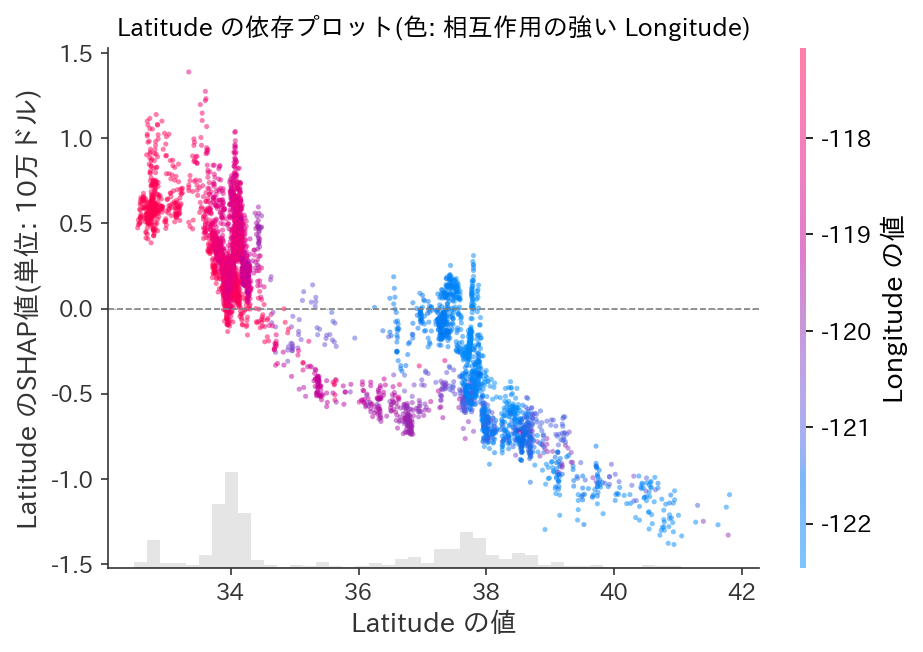

■ dependence_Longitude.png  [生成I/F: xai_platform.plots.dependence]


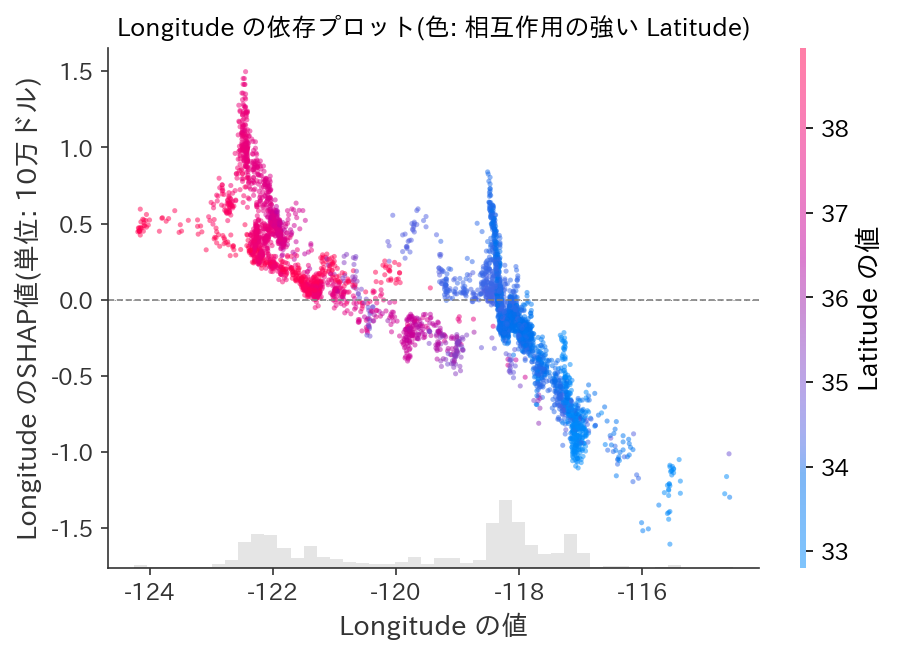

■ dependence_MedInc.png  [生成I/F: xai_platform.plots.dependence]


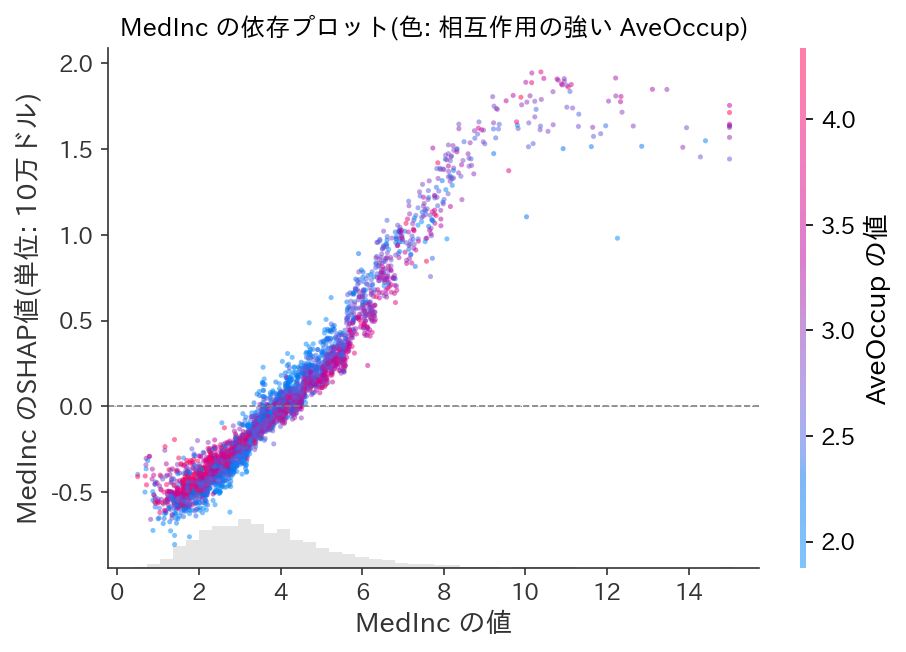

■ dependence_AveOccup.png  [生成I/F: xai_platform.plots.dependence]


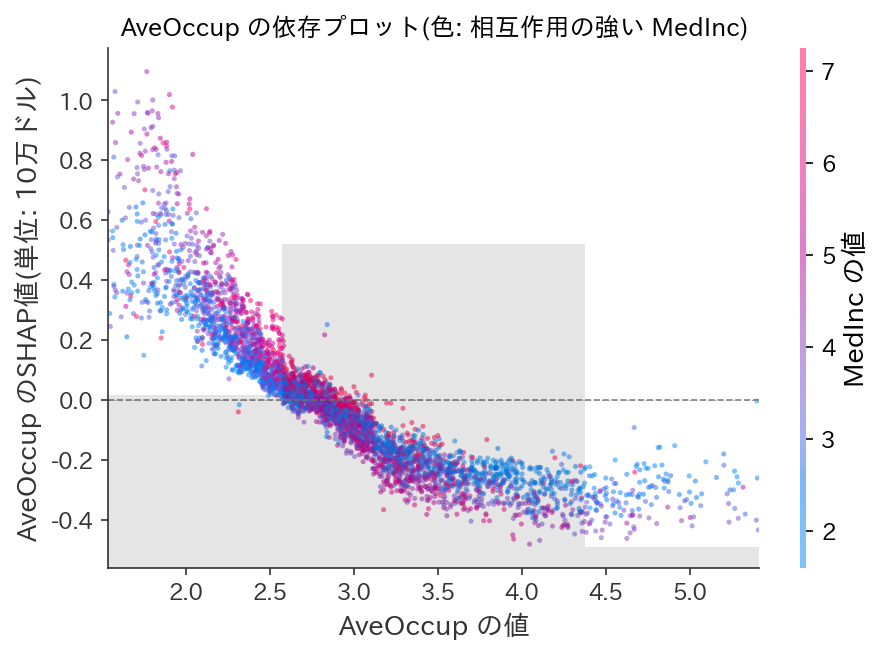

■ dependence_AveRooms.png  [生成I/F: xai_platform.plots.dependence]


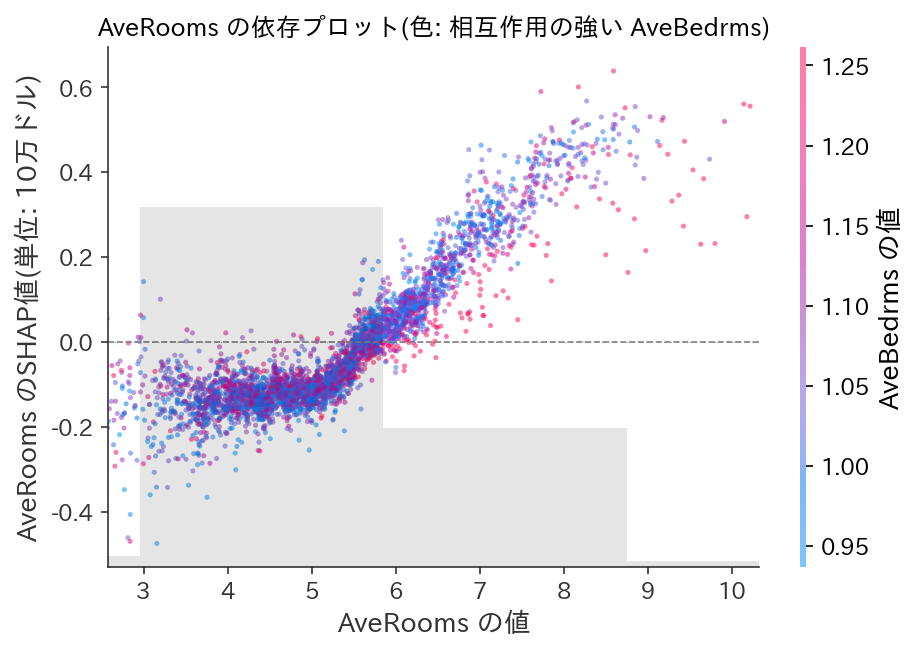

■ dependence_HouseAge.png  [生成I/F: xai_platform.plots.dependence]


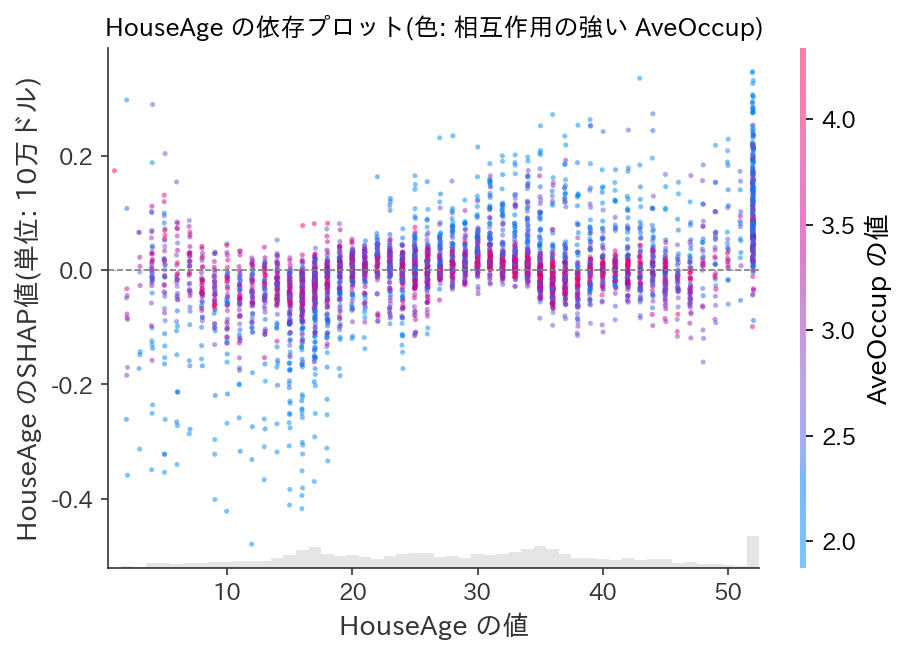

In [9]:
A.step_dependence().show()

### 6.3 相互作用(`shap_interaction_values`)

計算が重いため、テストデータから1,000件をサブサンプルして計算します(SEED=42)。ペアの強さは平均|φ_ij + φ_ji|で表します。φ_ijはペアの効果を対称に半分ずつ持っているため、2つを足しています。

相互作用値の行和とSHAP値の最大差: 3.04e-14
■ 相互作用の強さ(上位8)  [生成I/F: xai_platform.explain.interaction_strength]


,特徴量1,特徴量2,平均|相互作用|
0,Latitude,Longitude,0.3433
1,MedInc,AveOccup,0.0613
2,MedInc,AveRooms,0.0524
3,HouseAge,AveOccup,0.0511
4,AveOccup,Latitude,0.0490
5,MedInc,Longitude,0.0489
6,AveOccup,Longitude,0.0460
7,MedInc,HouseAge,0.0427


■ 主効果と相互作用分  [生成I/F: xai_platform.explain.main_vs_interaction]


,平均|SHAP|,平均|主効果|,平均|相互作用分|
Latitude,0.4240,0.3622,0.1884
Longitude,0.3682,0.3269,0.1843
MedInc,0.3356,0.3613,0.0691
AveOccup,0.1871,0.1937,0.0624
AveRooms,0.1325,0.1259,0.0447
HouseAge,0.0465,0.0420,0.0517
Population,0.0283,0.0235,0.0226
AveBedrms,0.0243,0.0154,0.0272


■ interaction_heatmap.png  [生成I/F: xai_platform.plots.interaction_heatmap]


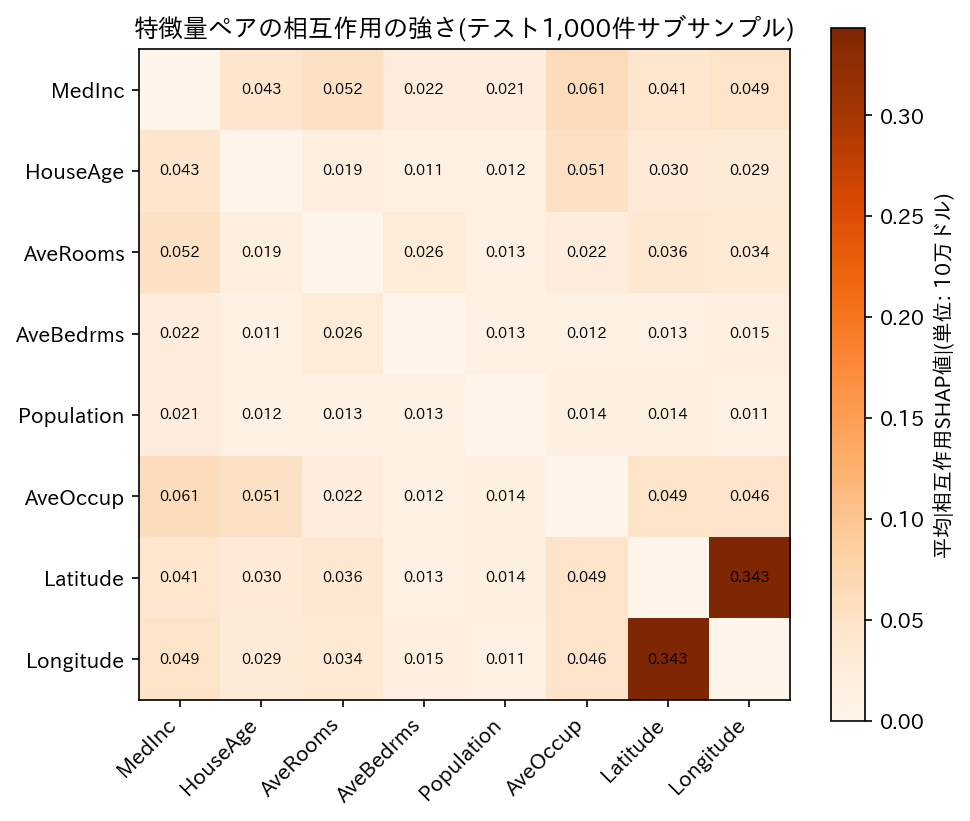

■ interaction_Latitude_Longitude.png  [生成I/F: xai_platform.plots.interaction_pair]


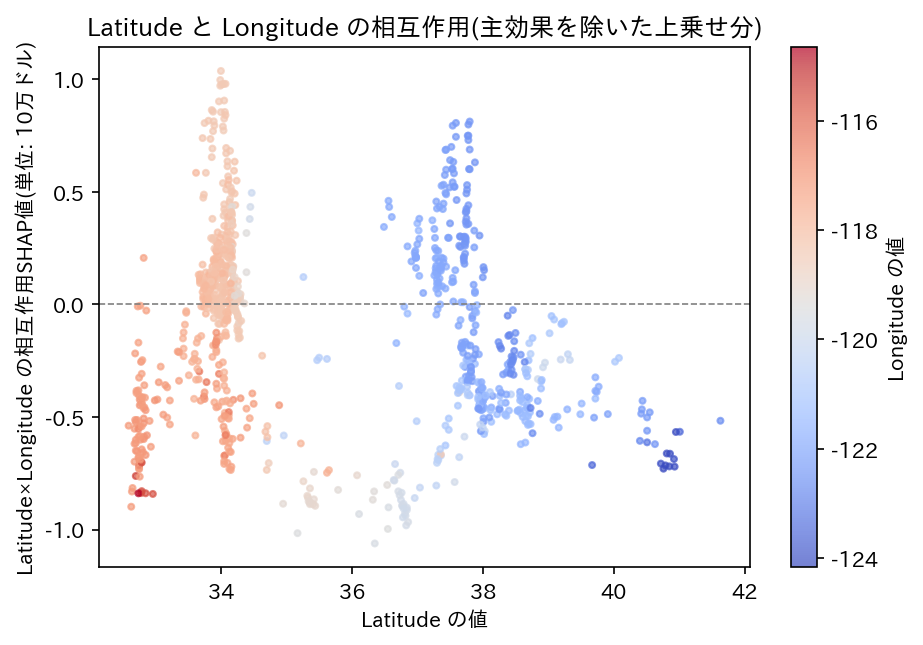

■ interaction_MedInc_AveOccup.png  [生成I/F: xai_platform.plots.interaction_pair]


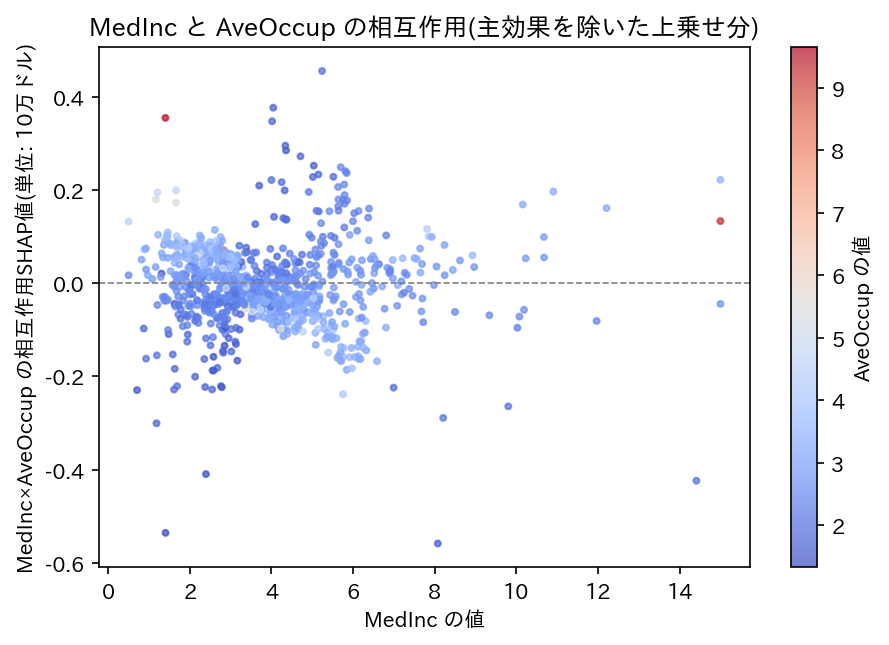

■ interaction_MedInc_AveRooms.png  [生成I/F: xai_platform.plots.interaction_pair]


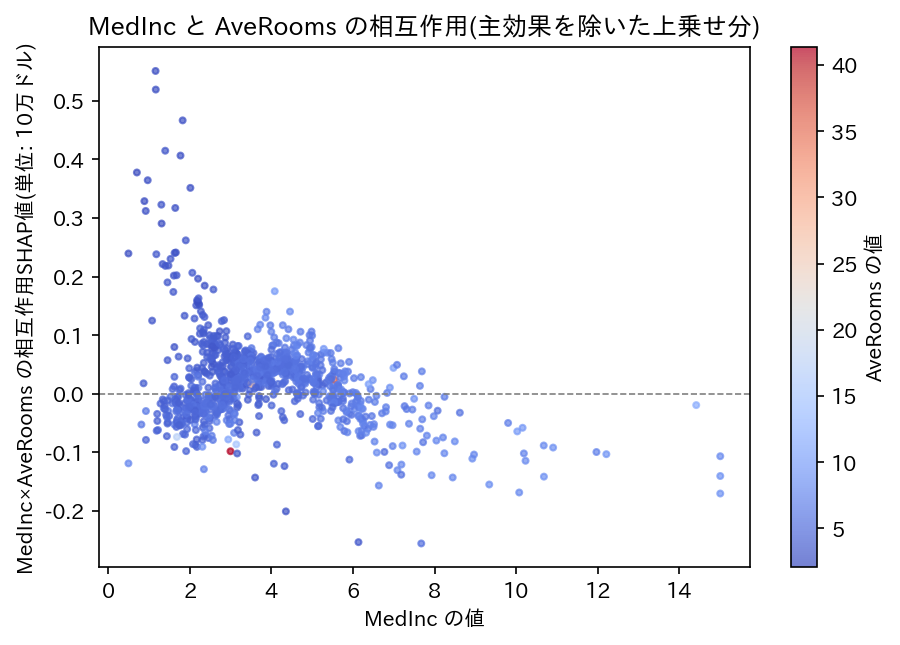

In [10]:
A.step_interactions().show()

### 6.4 予測値全体の構成(特徴量グループ別の積み上げ)

グループは `config.FEATURE_GROUPS` で定義しています。

| グループ | 特徴量 |
|---|---|
| 所得 | MedInc |
| 立地 | Latitude + Longitude |
| 住居 | AveRooms + AveBedrms + AveOccup |
| 築年 | HouseAge |
| 人口 | Population |

■ 予測値の十分位ビン別の平均寄与  [生成I/F: xai_platform.explain.group_by_prediction_bins]


,所得,立地,住居,築年,人口,予測値,件数,予測値の範囲
ビン,,,,,,,,
0,-0.4406,-0.7332,-0.1702,-0.0081,-0.0069,0.7129,413,0.39–0.89
1,-0.3447,-0.5791,-0.1100,-0.0120,0.0000,1.0262,413,0.90–1.14
2,-0.2636,-0.4223,-0.1150,-0.0132,0.0026,1.2605,413,1.14–1.39
3,-0.2165,-0.1845,-0.1675,-0.0037,0.0045,1.5042,412,1.39–1.61
4,-0.1308,-0.0545,-0.1598,-0.0093,0.0041,1.7217,413,1.61–1.83
5,-0.0894,0.0778,-0.0873,-0.0137,0.0024,1.9618,413,1.83–2.10
6,0.0206,0.1835,-0.0178,-0.0131,0.0065,2.2516,412,2.10–2.42
7,0.1573,0.3204,0.0717,-0.0055,0.0070,2.6228,413,2.42–2.86
8,0.3316,0.5546,0.2302,0.0206,0.0020,3.2110,413,2.87–3.61


■ group_stack_deciles.png  [生成I/F: xai_platform.plots.group_stack_bins]


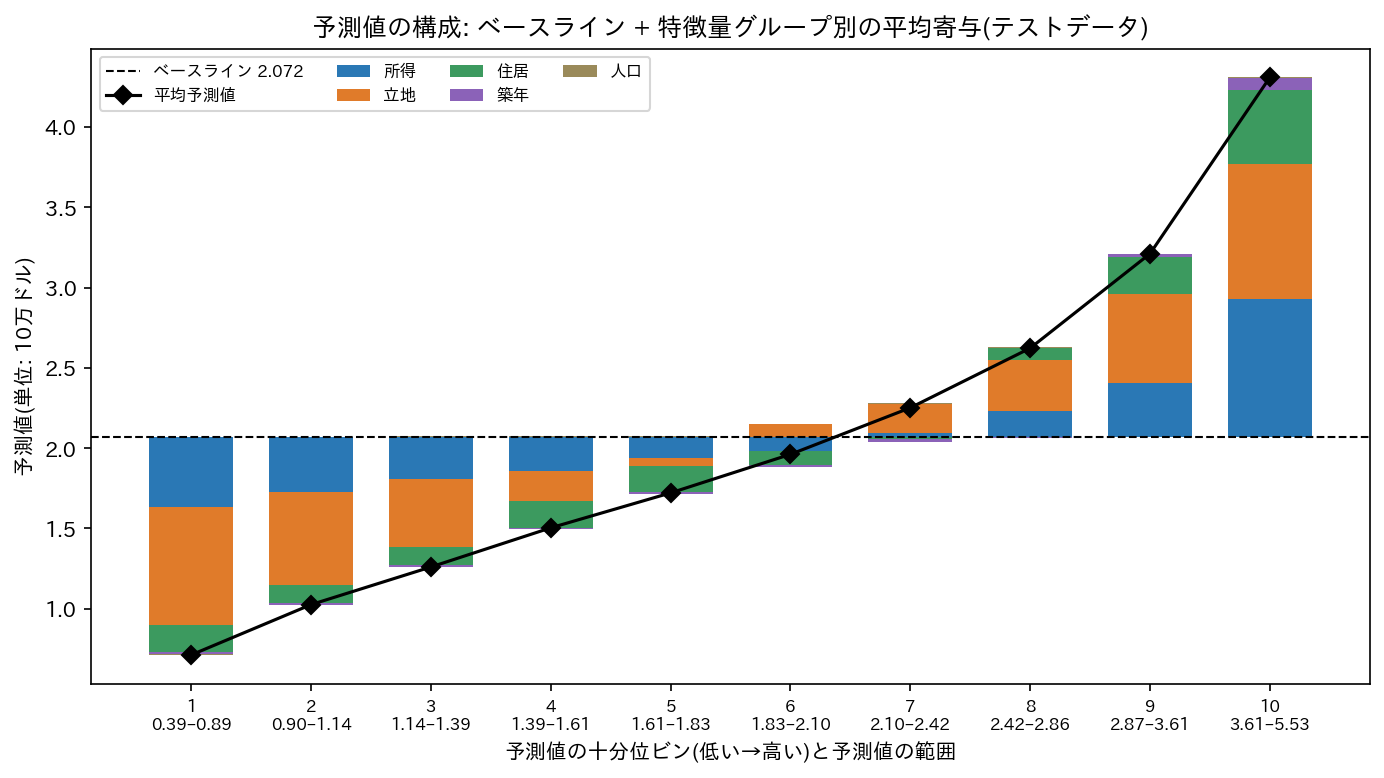

■ group_stack_sorted.png  [生成I/F: xai_platform.plots.group_stack_sorted]


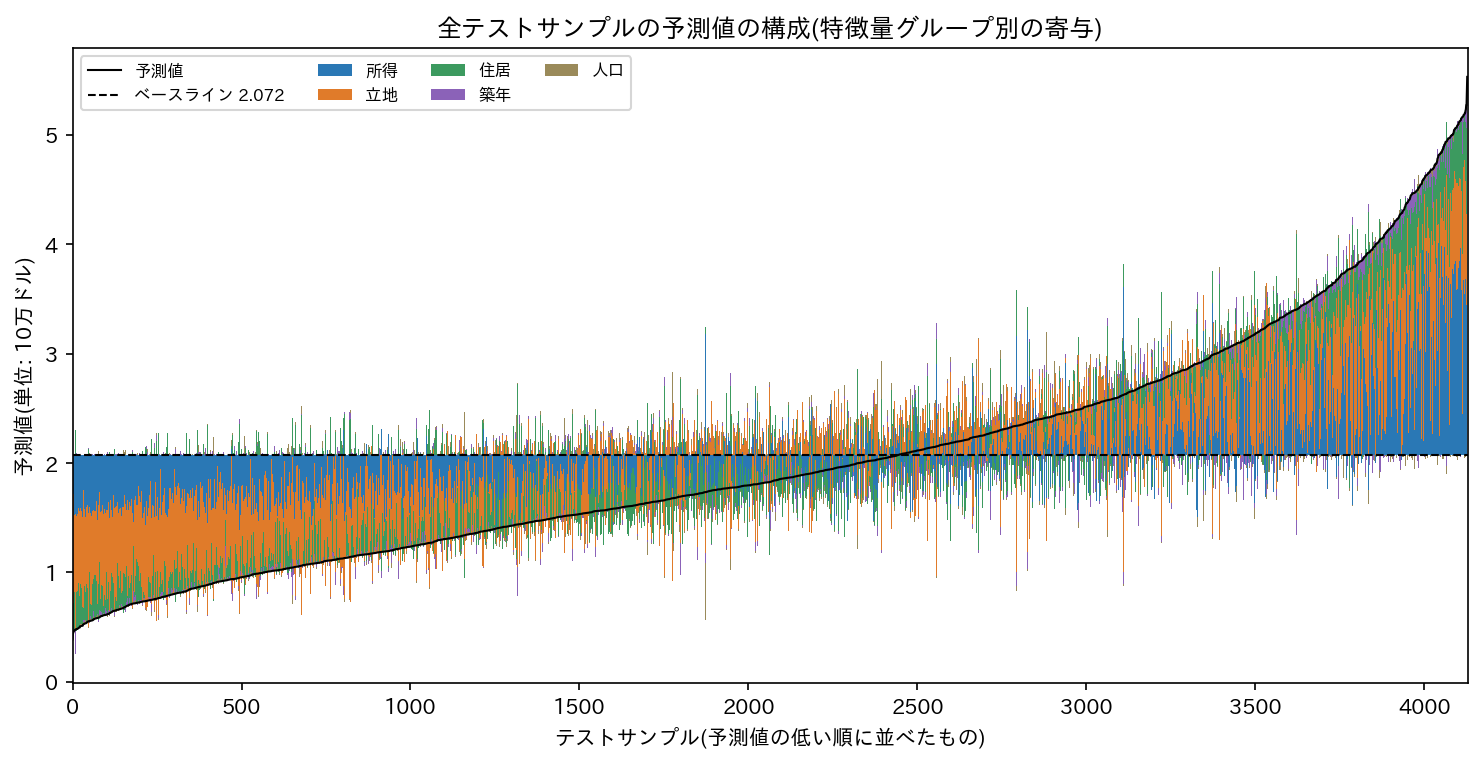

In [11]:
A.step_groups().show()

In [12]:
A.save_key_results().show()

saved C:\d\takashi\python\github\learning_v2\xai\shap\outputs\tables\key_results.json


## 7. 出力ファイルと生成I/Fの対応

各出力ファイルを作成したプラットフォームI/F(`xai_platform.*`)と、それを呼び出したアプリ側のステップを、`outputs/manifest.csv` と `outputs/manifest.md` に書き出します。この記録は自動で行われます。表を返すI/Fには `@produces_table`、図を保存するI/Fには `@produces_figure` を付けてあり、保存した時点で記録されます。

In [13]:
A.save_manifest().show()

saved C:\d\takashi\python\github\learning_v2\xai\shap\outputs\manifest.csv
saved C:\d\takashi\python\github\learning_v2\xai\shap\outputs\manifest.md
■ 出力ファイルと生成I/F


,ファイル,種類,生成I/F,I/Fの説明,SHAP描画関数,分析ステップ
0,tables/feature_descriptions.csv,表,xai_platform.data.description_table,特徴量名 → 説明 の辞書を表にする。,,CaliforniaAnalysis.step_data
1,tables/model_performance.csv,表,xai_platform.model.evaluation_table,複数モデルのテストデータでの R²・RMSE・MAE の表。,,CaliforniaAnalysis.step_models
2,tables/additivity_check_test.csv,表,xai_platform.explain.additivity_check,加法性チェック: 各サンプルの |ベースライン + ΣSHAP − predict| と合否の表。,,CaliforniaAnalysis.step_shap_validation
3,tables/ridge_shap_vs_coef.csv,表,xai_platform.explain.linear_shap_check,線形モデルのSHAP値が 係数 × (x − 訓練平均) と一致するかの検証表。,,CaliforniaAnalysis.step_shap_validation
4,tables/representative_samples.csv,表,xai_platform.explain.select_representatives,予測値の分位点に最も近いサンプルを選ぶ。quantiles は {区分ラベル: 分位点}。,,CaliforniaAnalysis.step_micro
5,tables/decomposition_high.csv,表,xai_platform.explain.decomposition_table,1サンプルの分解表(現在の値・SHAP値・累積。最終行が ベースライン + ΣSHAP = ...,,CaliforniaAnalysis.step_micro
6,figures/waterfall_high.png,図,xai_platform.plots.waterfall,1サンプルの予測値を「ベースライン + 各特徴量の寄与」に分解したウォーターフォール図。,shap.plots.waterfall,CaliforniaAnalysis.step_micro
7,tables/decomposition_median.csv,表,xai_platform.explain.decomposition_table,1サンプルの分解表(現在の値・SHAP値・累積。最終行が ベースライン + ΣSHAP = ...,,CaliforniaAnalysis.step_micro
8,figures/waterfall_median.png,図,xai_platform.plots.waterfall,1サンプルの予測値を「ベースライン + 各特徴量の寄与」に分解したウォーターフォール図。,shap.plots.waterfall,CaliforniaAnalysis.step_micro
9,tables/decomposition_low.csv,表,xai_platform.explain.decomposition_table,1サンプルの分解表(現在の値・SHAP値・累積。最終行が ベースライン + ΣSHAP = ...,,CaliforniaAnalysis.step_micro
